In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths


In [2]:
df = pd.read_csv('Extinction_Control.csv')

print(df)

    Group       LTM     LTM 2     LTM 3      LTM4 Control
0       1  0.108000  0.018000  0.078000  0.051333       n
1       4 -0.076000  0.061333 -0.076667 -0.042040       n
2       6  0.647333  0.215007  0.344123  0.017333       n
3       7  0.760667  0.333333  0.427933  0.526667       n
4       8  0.406000  0.158000  0.318000 -0.148267       n
5       9  0.786000  0.218387  0.321253  0.290000       n
6      10  0.714667  0.327314  0.402310  0.120100       n
7      11  0.658200  0.264247  0.231231 -0.122000       n
8      12  0.637333  0.538667  0.205250  0.101000       n
9      13  0.592667  0.221000  0.319841  0.142120       n
10     14  0.676667  0.304510  0.522000  0.082100       n
11     15  0.544267  0.271734  0.604800  0.041211       n
12     16  0.297333  0.012000  0.120000 -0.152100       n
13     17  0.789200  0.465421  0.351100  0.108210       n
14     18  0.487333  0.253082  0.379052 -0.081200       n
15     19  0.056000 -0.037333  0.579333  0.426667       y
16     20  0.1

In [3]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


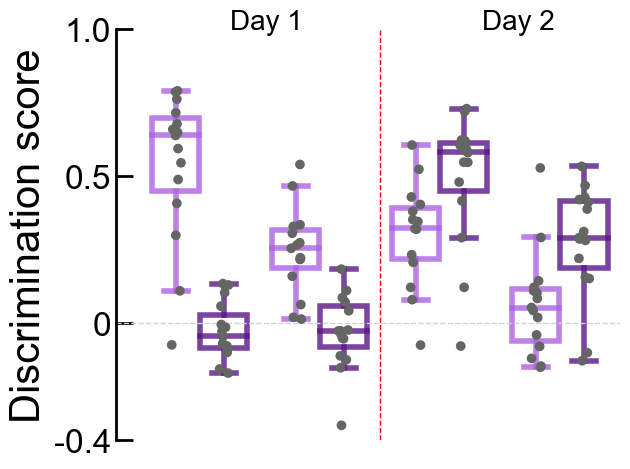

In [21]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}


colors_boxplot = ['#ad62e3','#581787']
colors = ["#646664","#646664"]

boxplot = sns.boxplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    fliersize=0,
    linewidth=4,
    **PROPS
)

ax = sns.stripplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    size=7,
    facecolors='none',
    edgecolors='black',
    palette=colors,
    jitter=0.09,
    dodge=True
)
plt.axhline(linewidth=1, color='lightgrey',ls='--')
plt.axvline(x=1.5,linewidth=1, color='red',ls='--')
ax.legend().set_visible(False)

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[i%2]
    patch.set_edgecolor(col)
    patch.set_facecolor('None')
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE


#ax.set_xticklabels(['Recall 1','Recall 2', 'Recall 1', 'Recall 2'],fontname="Arial", fontsize=20)
ax.set_xticklabels(['','', '', ''],fontname="Arial", fontsize=20)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(2)


ax.text(0.25,1,'Day 1',fontname="Arial",fontsize=20)
ax.text(2.35,1,'Day 2',fontname="Arial",fontsize=20)
ax.set_xlabel("",fontsize=20,fontname="Arial")
ax.set_ylabel("Discrimination score",fontsize=30,fontname="Arial")

ax.set_ylim([-0.4000999,1])
ax.set_xlim([-0.7,3.5])

ax.set_yticks([-0.4,0,0.5,1], fontname='Arial')
ax.set_yticklabels(['-0.4','0','0.5','1.0'],fontname='Arial')
ax.tick_params(axis='y', which='major', direction='in',length=12, labelsize=24, width=2)

plt.tick_params(bottom = False)

fig = ax.get_figure()
plt.tight_layout()
fig.tight_layout()

fig.savefig("Fig3_Extinction_Both.jpg",dpi=600,bbox_inches='tight')
plt.savefig('Fig3_Extinction_Both.eps', dpi=600, format='eps')



In [22]:
newdf_1 = newdf.loc[newdf['control']=='y']

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


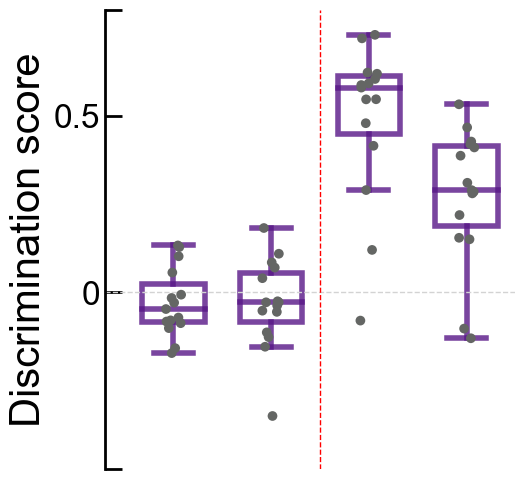

In [23]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}


colors_boxplot = ['#ad62e3','#581787']
colors = ["#646664"]

boxplot = sns.boxplot(
    data=newdf_1,
    x='Experimental Condition',
    y='Left preference',
    fliersize=0,
    linewidth=4,
    **PROPS
)

ax = sns.stripplot(
    data=newdf_1,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    size=7,
    facecolors='none',
    edgecolors='black',
    palette=colors,
    jitter=0.09,
    dodge=True
)
plt.axhline(linewidth=1, color='lightgrey',ls='--')
plt.axvline(x=1.5,linewidth=1, color='red',ls='--')
ax.legend().set_visible(False)

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[1]
    patch.set_edgecolor(col)
    patch.set_facecolor('None')
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE


#ax.set_xticklabels(['Recall 1','Recall 2', 'Recall 1', 'Recall 2'],fontname="Arial", fontsize=20)
ax.set_xticklabels(['','','',''],fontname="Arial", fontsize=20)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(2)


#ax.text(0.25,1,'Day 1',fontname="Arial",fontsize=20)
#ax.text(2.35,1,'Day 2',fontname="Arial",fontsize=20)
ax.set_xlabel("",fontsize=20,fontname="Arial")
ax.set_ylabel("Discrimination score",fontsize=30,fontname="Arial")

ax.set_ylim([-0.5,0.8])
ax.set_xlim([-0.7,3.5])

ax.set_yticks([-0.5,0,0.5,0.8], fontname='Arial')
ax.set_yticklabels(['',0,'0.5',''],fontname='Arial')
ax.tick_params(axis='y', which='major', direction='in',length=12, labelsize=24, width=2)

plt.tick_params(bottom = False)

fig = ax.get_figure()
#fig.set_size_inches([6,5])
plt.tight_layout()
fig.tight_layout()
adjust_box_widths(fig, 0.8)
fig.set_size_inches(5.1,4.9)
fig.savefig("Fig3_Extinction_Control.jpg",dpi=600,bbox_inches='tight')
plt.savefig('Fig3_Extinction_Control.eps', dpi=600, format='eps')



In [24]:
newdf_2 = newdf.loc[newdf['control']=='n']

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


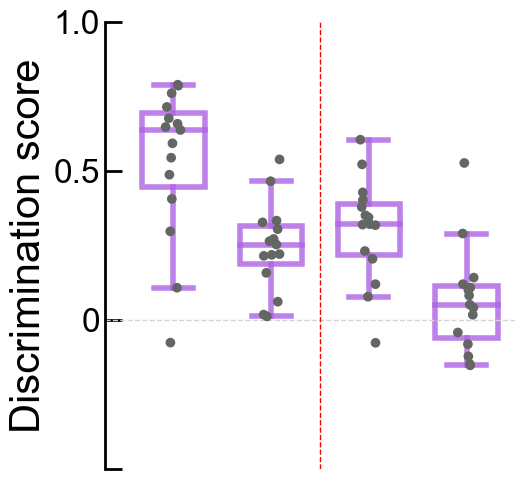

In [25]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}


colors_boxplot = ['#ad62e3','#581787']
colors = ["#646664"]

boxplot = sns.boxplot(
    data=newdf_2,
    x='Experimental Condition',
    y='Left preference',
    fliersize=0,
    linewidth=4,
    **PROPS
)

ax = sns.stripplot(
    data=newdf_2,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    size=7,
    facecolors='none',
    edgecolors='black',
    palette=colors,
    jitter=0.09,
    dodge=True
)
plt.axhline(linewidth=1, color='lightgrey',ls='--')
plt.axvline(x=1.5,linewidth=1, color='red',ls='--')
ax.legend().set_visible(False)

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[0]
    patch.set_edgecolor(col)
    patch.set_facecolor('None')
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE


#ax.set_xticklabels(['Recall 1','Recall 2', 'Recall 1', 'Recall 2'],fontname="Arial", fontsize=20)
ax.set_xticklabels(['','','',''],fontname="Arial", fontsize=20)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(2)


#ax.text(-0.25,1,'Social 1    Social 2',fontname="Arial",fontsize=20)
#ax.text(2.35,1,'Social 3    Social 4',fontname="Arial",fontsize=20)
ax.set_xlabel("",fontsize=20,fontname="Arial")
ax.set_ylabel("Discrimination score",fontsize=30,fontname="Arial")

ax.set_ylim([-0.5,1])
ax.set_xlim([-0.7,3.5])

ax.set_yticks([-0.5,0,0.5,1], fontname='Arial')
ax.set_yticklabels(['','0','0.5','1.0'],fontname='Arial')
ax.tick_params(axis='y', which='major', direction='in',length=12, labelsize=24, width=2)

plt.tick_params(bottom = False)

fig = ax.get_figure()
plt.tight_layout()
fig.tight_layout()
adjust_box_widths(fig, 0.8)
fig.set_size_inches(5.1,4.9)

fig.savefig("Fig3_Extinction_Main.jpg",dpi=600,bbox_inches='tight')
plt.savefig('Fig3_Extinction_Main.eps', dpi=600, format='eps')
